# 4 · Relation questions: the graph's home turf - and an honest null result

*Part 4 of the story. Previously: `03_when_does_the_graph_pay_off.ipynb`.*

**What this notebook answers.** The six relation questions ask for links *between*
senses ("which sense of X is the synonym / hypernym / antonym of this given sense?").
Only the graph layer stores such links explicitly, so this is where the graph
should shine. Does it?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


FULL = al.find_run("skeleton")
CAP3 = al.find_run("cap3")
full = al.load_answers(FULL)
cap3 = al.load_answers(CAP3)
senses = al.load_senses_table().set_index("sense_id")
questions = al.load_questions_table().set_index("question_id")

rel_q = al.load_questions_table()
rel_q = rel_q[rel_q["question_type"] == "relation"].copy()
rel_q["gold definition"] = rel_q["gold_sense_id"].map(lambda s: senses.loc[s, "definition"][:52])
rel_q[["question_id", "relation", "lemma", "gold_sense_id", "related_sense_id", "gold definition"]]

,question_id,relation,lemma,gold_sense_id,related_sense_id,gold definition
30,q-031,synonym,mišičnjak,16601918,8150276,"moški z močno razvitimi mišicami | moški z močnimi,"
31,q-032,synonym,pendrek,16180010,8154129,"policijska palica | palica, ki jo policisti in drugi"
32,q-033,synonym,zenit,16189942,8154207,"o točki na nebu | najvišja točka na nebu, ki je navp"
33,q-034,hypernym,tolkalo,16194507,8161886,"vrsta glasbila | glasbilo, pri katerem zvok nastane"
34,q-035,hypernym,zapor,16258980,16601485,prostor; ustanova
35,q-036,antonym,revščina,16253194,16254790,o stanju finančnega pomanjkanja


In [2]:
def context_block(prompt: str) -> str:
    return prompt.split("Možni pomeni:")[1].split("Odgovori natanko")[0].strip()

qid = "q-034"  # cinela -> tolkalo (hypernym); capped run = evidence-first ranking
for v in ["C", "D"]:
    row = cap3[(cap3["variant"] == v) & (cap3["question_id"] == qid)].iloc[0]
    block = context_block(row["prompt"])
    print("=" * 30, al.VARIANT_LABELS[v], "=" * 30)
    print(block[:750] + (" …" if len(block) > 750 else ""))
    print()

============================== C - dictionary list ==============================
ID: 16194507
Beseda: tolkalo (noun)
Definicija: vrsta glasbila | glasbilo, pri katerem zvok nastane z udarcem, tresenjem ali drgnjenjem
Zveze: afriška tolkala, indijska tolkala, klasična tolkala, lesena tolkala, mojster tolkal, igranje na tolkala, skladba za tolkala, igrati na tolkala

ID: 16194517
Beseda: tolkalo (noun)
Definicija: igranje tolkal | glasbilo, ki daje zvok z udarjanjem, tresenjem ali drgnjenjem
Zveze: študij tolkal, profesor tolkal, poučevati tolkala, študirati tolkala

ID: 16194522
Beseda: tolkalo (noun)
Definicija: glasbenik | glasbilo, na katero se igra z udarjanjem, potresavanjem ali drgnjenjem
Zveze: spremljava tolkal

============================== D - graph-ranked ==============================
ID: 16194507
Beseda: tolkalo (noun)
Definicija: vrsta glasbila | glasbilo, pri katerem zvok nastane z udarcem, tresenjem ali drgnjenjem
Zveze: afriška tolkala, igranje na tolkala, igrati na t

> **What we see.** C shows the candidate senses of *tolkalo* with definitions,
> synonyms and collocations - but nothing that says "this one is the hypernym
> of *činela*". D shows the same blocks **plus one extra line** on the linked
> candidate: `Graf: ta pomen je nadpomenka pomena 8161886.` That line is the
> graph's unique contribution: an explicit, verified join between two senses.
> (Both excerpts below come from the capped run, where the evidence-first
> ranking places the linked candidate first.)

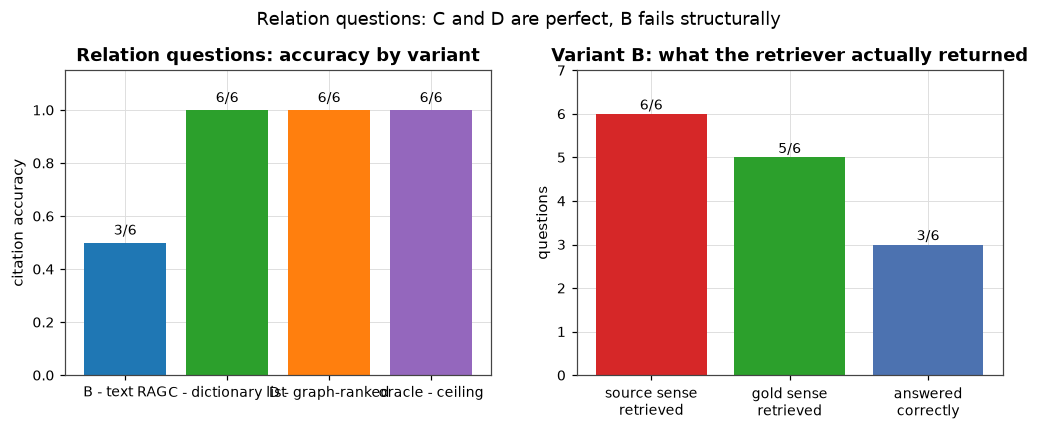

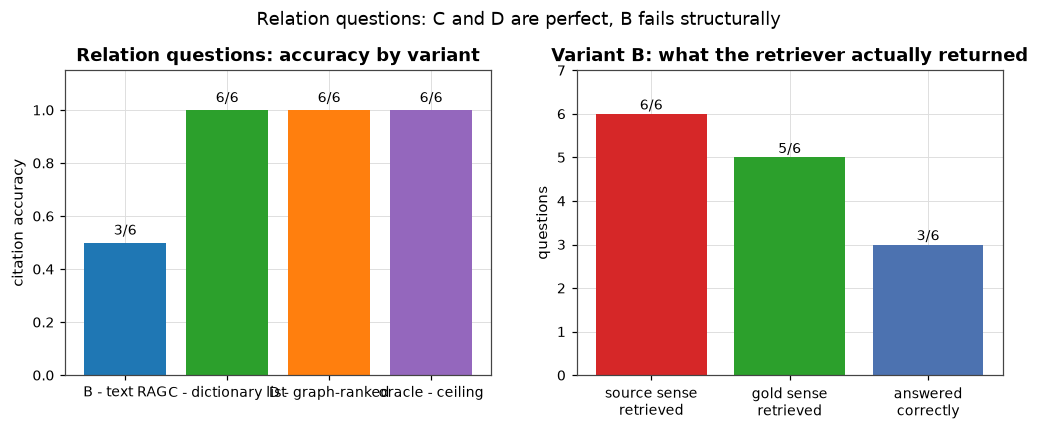

In [3]:
rel = full[full["question_type"] == "relation"]
n_rel = int((rel["variant"] == "B").sum())
rel_acc = {v: float(rel[rel["variant"] == v]["correct"].sum()) / n_rel for v in ["B", "C", "D", "oracle"]}

b_rel = rel[rel["variant"] == "B"]
related_hit = int(sum(str(r["related_sense_id"]) in r["retrieved_ids"] for _, r in b_rel.iterrows()))
gold_hit = int(sum(r["gold_sense_id"] in r["retrieved_ids"] for _, r in b_rel.iterrows()))
b_correct = int(b_rel["correct"].sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
order = ["B", "C", "D", "oracle"]
ax.bar([al.VARIANT_LABELS[v] for v in order], [rel_acc[v] for v in order], color=[al.VARIANT_COLORS[v] for v in order])
for i, v in enumerate(order):
    ax.text(i, rel_acc[v] + 0.03, f"{int(round(rel_acc[v] * n_rel))}/{n_rel}", ha="center", fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_ylabel("citation accuracy")
ax.set_title("Relation questions: accuracy by variant")

ax = axes[1]
labels = ["source sense\nretrieved", "gold sense\nretrieved", "answered\ncorrectly"]
vals = [related_hit, gold_hit, b_correct]
ax.bar(labels, vals, color=["#d62728", "#2ca02c", "#4c72b0"])
for i, v in enumerate(vals):
    ax.text(i, v + 0.1, f"{v}/{n_rel}", ha="center", fontsize=9)
ax.set_ylim(0, 7)
ax.set_ylabel("questions")
ax.set_title("Variant B: what the retriever actually returned")

fig.suptitle("Relation questions: C and D are perfect, B fails structurally", y=1.03)
al.save_figure(fig, "04_relation_results")
fig

> **Reading the chart.** C, D and oracle answer **6/6**; B answers **3/6**.
> B's failure is structural, not accidental: the question text *quotes the
> source sense's definition*, so embedding search reliably retrieves the
> **source** (6/6), and the gold sense lands in the top-10 in 5/6 - yet only
> 3/6 are answered correctly: one question never retrieved the gold, and two
> more ended in a wrong citation (of the source or a neighbour) or a refusal.
> Being somewhere in the list is not enough when the source sits at the top.

In [4]:
rows = []
for _, r in b_rel.sort_values("question_id").iterrows():
    top = []
    for sid in r["retrieved_ids"][:3]:
        tag = ""
        if sid == r["gold_sense_id"]:
            tag = " (GOLD)"
        elif str(sid) == str(r["related_sense_id"]):
            tag = " (source)"
        top.append(sid + tag)
    rows.append({
        "question": r["question_id"],
        "relation": r["relation"],
        "B top-3 retrieved": " | ".join(top),
        "B cited": "none" if pd.isna(r["cited_sense_id"]) else r["cited_sense_id"],
        "B correct": bool(r["correct"]),
    })
pd.DataFrame(rows)

,question,relation,B top-3 retrieved,B cited,B correct
0,q-031,synonym,8150276 (source) | 8186904 | 8176238,8150276,False
1,q-032,synonym,8154129 (source) | 16180010 (GOLD) | 16180020,16180010,True
2,q-033,synonym,8154207 (source) | 16189942 (GOLD) | 16618475,16189942,True
3,q-034,hypernym,16194517 | 8161886 (source) | 16194507 (GOLD),16194507,True
4,q-035,hypernym,16601485 (source) | 16650833 | 16604082,16604082,False
5,q-036,antonym,16254790 (source) | 16599747 | 16253195,none,False


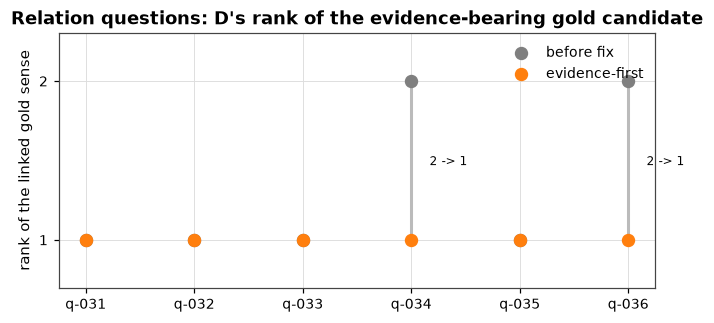

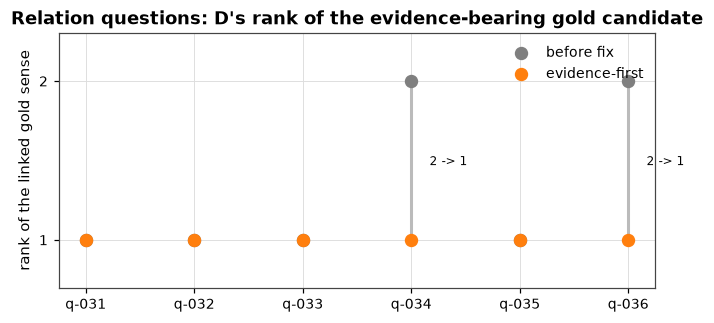

In [5]:
def rel_ranks(run_id):
    d = al.load_answers(run_id)
    d = d[(d["variant"] == "D") & (d["question_type"] == "relation")].set_index("question_id")
    return d["gold_rank"].astype(int)

before = rel_ranks(FULL)  # executed before the evidence-first ranking fix
after = rel_ranks(CAP3)   # capped runs: evidence-bearing candidates ranked first

fig, ax = plt.subplots(figsize=(7.0, 3.0))
qs = sorted(before.index)
for i, qid in enumerate(qs):
    b, a = int(before[qid]), int(after[qid])
    ax.plot([i, i], [b, a], "-", color="#bbbbbb", lw=2, zorder=1)
    ax.scatter([i], [b], s=60, color="#7f7f7f", zorder=2, label="before fix" if i == 0 else None)
    ax.scatter([i], [a], s=60, color=al.VARIANT_COLORS["D"], zorder=3, label="evidence-first" if i == 0 else None)
    if b != a:
        ax.annotate(f"{b} -> {a}", (i, (b + a) / 2), textcoords="offset points", xytext=(12, -3), fontsize=8)
ax.set_xticks(range(len(qs)), qs)
ax.set_yticks([1, 2])
ax.set_ylim(0.7, 2.3)
ax.set_ylabel("rank of the linked gold sense")
ax.set_title("Relation questions: D's rank of the evidence-bearing gold candidate")
ax.legend(loc="upper right")
al.save_figure(fig, "04_evidence_first")
fig

> **What we see.** In the first run, D *displayed* the graph evidence but did
> not use it for ranking: two gold senses sat at rank 2 (they still answered
> correctly, because everything was shown). After the fix, the evidence-bearing
> candidate is always rank 1 - which is why relations stay 6/6 even at budget 1
> (where C loses one, q-036). Displaying a join is not the same as using it.

## The honest finding: the graph was not needed here

C - which has **no access to any link** - also answered 6/6. The reason is our
pair selection: to keep the drafts verifiable, the six pairs have definitions
that overlap lexically (činela's definition literally contains "tolkalo";
jetnišnica's contains "zapor"), and all gold senses sit in the first 2
dictionary positions. A model reading the definitions can reconstruct the
relation without the edge.

**So what did we learn?** In the language of notebook 3, the relation pack is
the *extreme case* of the payoff rule: the cue (the link) is always present, so
the ranking can always act - but when the cue is also recoverable from the text
(C's situation), the graph adds robustness, not accuracy. Explicit edges become
necessary when the text **cannot** carry the relation: definitions that do not
overlap, linked senses outside the first slots, or relations not derivable from
wording. That is a concrete design spec for a **relation pack v2**
(definition-disjoint pairs, hand-verified).

> **Takeaway.** Graph links are a retrieval/selection device, not a reasoning
> device - they matter exactly when text similarity cannot recover the join.